# Reproducing the Talens et al. (2026) PLATO benchmark with TLS + GP

**Level:** intermediate · **Run time:** about 2 min on a laptop for the default 3 stars per sample; the full benchmark (4500 searches) takes about 30-45 min on one GPU, or about half a day on a 16-core CPU · **Needs:** `pandas`, `pyarrow`, `batman-package`, and 4 GB of disk space for the data.

[Talens et al. (2026)](https://arxiv.org/abs/2609.15493) simulated two years of PLATO photometry for 2000 stars from the PLATO Input Catalogue, with photon noise, granulation, oscillations, starspots and instrumental systematics, and injected one planet of 0.5-2 Earth radii into each light curve. They compared light curve filters and three search codes: CETRA, `umbra` and `nuance` (a GP search). Two samples were injected separately:

* **inner**: periods of 0.8-300 d, about three or more transits;
* **outer**: periods of 113-700 d, one to three transits (the hard case: Earth analogues).

Without a detection threshold, `nuance` recovered 68.7 % (inner) and 53.8 % (outer) of the planets with a single configuration, the best of the three codes; CETRA and `umbra` came close or exceeded it only with a union of several filter windows.

The planet-free light curves and the planet catalogues are public. This notebook injects the planets, searches each light curve with TLS 2.0 + GP (`transitleastsquares.gp`), and counts the recoveries with their criteria. The code is in [`talens_benchmark.py`](talens_benchmark.py) next to this notebook, which also runs the full benchmark from the command line, in parallel.

## Settings

`N_STARS` is the number of stars per sample (inner, outer, planet-free). The default of 3 runs 9 searches in about 2 minutes. Set it to `None` for the full benchmark: 2000 + 2000 injections and 500 planet-free light curves. Finished searches are stored in `RESULTS` and skipped when the notebook is run again, so an interrupted run continues where it stopped. For the full run, the command line is more convenient (several processes, which can share one GPU):

    python talens_benchmark.py DATA_DIR results.jsonl --device gpu --workers 8

In [1]:
N_STARS = 3                   # stars per sample; None: all (2000 inner, 2000 outer, 500 planet-free)
DATA_DIR = "talens2026"       # the unzipped data, see below
RESULTS = "talens_results.jsonl"
WORKERS = 1                   # parallel processes (for long runs; several can share a GPU)

import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams; rcParams["figure.dpi"] = 120
from transitleastsquares import gp, gpu
import warnings
warnings.filterwarnings("ignore", message="Grid size")   # numba-cuda: low occupancy on the short segments
import talens_benchmark as tb

DEVICE = "gpu" if gpu.available() else "cpu"
print("device:", DEVICE)

device: gpu


## The data

Download from the Oxford University Research Archive ([doi:10.5287/ora-aeaxy98vd](https://doi.org/10.5287/ora-aeaxy98vd)):
* `full-noplanet.zip` (1.5 GB; 2.7 GB unzipped): the planet-free "full" light curves at 600 s cadence,
* `star_catalog.ftr`, `planet_catalog_inner.ftr`, `planet_catalog_outer.ftr`,

and unzip the zip file into `DATA_DIR`, so that it contains `lightcurves/full_noplanet/cadence_600s/0000000000.ftr` and the three catalogues.

In [2]:
for f in ("star_catalog.ftr", "planet_catalog_inner.ftr", "planet_catalog_outer.ftr",
          "lightcurves/full_noplanet/cadence_600s/0000000000.ftr"):
    assert os.path.exists(os.path.join(DATA_DIR, f)), f"missing: {os.path.join(DATA_DIR, f)}"
stars = tb.stars(DATA_DIR)
outer = tb.planets(DATA_DIR, "outer")
print(len(stars), "stars;", "outer sample: periods", outer["Period"].min().round(1), "-", outer["Period"].max().round(1), "d")

2000 stars; outer sample: periods 112.7 - 699.9 d


## Injection

We inject the planets ourselves into the planet-free light curves, with [batman](https://github.com/lkreidberg/batman): circular orbits, the nonlinear limb darkening of their catalogue, integrated over the 600 s exposures. This differs in detail from their simulations, where the transits were added at the native 25 s cadence and the light curves filtered before binning to 300 s; their own tests found practically the same recoveries for light curves binned to 600 s before filtering.

Here is star 0 with its outer planet, and its quarters (eight, with gaps; each has its own drift).

star 0: R = 1.39 R_sun, M = 1.25 M_sun; planet: P = 339.7 d, R_p = 0.85 R_earth, T14 = 15.8 h, depth about 32 ppm, 3 transits with data


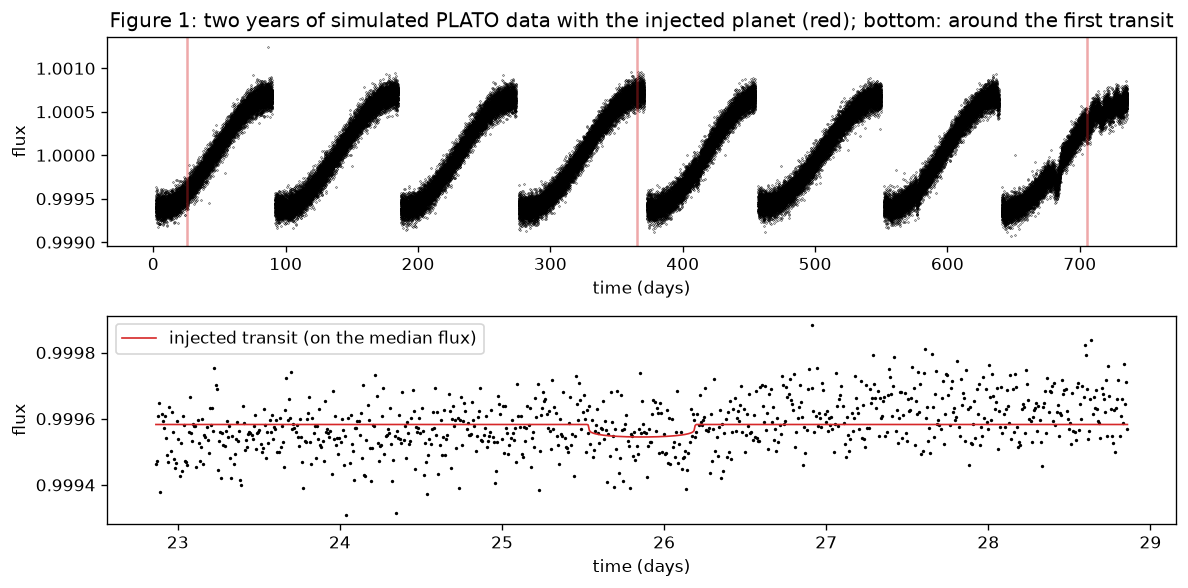

In [3]:
star = 0
t, f, e = tb.load(DATA_DIR, star)
row = outer.iloc[star]
fi = tb.inject(t, f, row)
T14 = tb.t14(row)
transits = tb.transits_with_data(t, row, T14)
print(f"star {star}: R = {stars['Radius'][star]:.2f} R_sun, M = {stars['Mass'][star]:.2f} M_sun; planet: P = {row['Period']:.1f} d, "
      f"R_p = {row['Rp_Rstar'] * stars['Radius'][star] * 109.1:.2f} R_earth, T14 = {24 * T14:.1f} h, "
      f"depth about {1e6 * row['Rp_Rstar']**2:.0f} ppm, {len(transits)} transits with data")

fig, ax = plt.subplots(2, 1, figsize=(10, 5))
ax[0].plot(t, fi, "k.", ms=0.5)
for tc in transits:
    ax[0].axvline(tc, color="tab:red", alpha=0.4)
ax[0].set_xlabel("time (days)"); ax[0].set_ylabel("flux")
ax[0].set_title("Figure 1: two years of simulated PLATO data with the injected planet (red); bottom: around the first transit")
w = np.abs(t - transits[0]) < 3
ax[1].plot(t[w], fi[w], "k.", ms=2)
ax[1].plot(t[w], fi[w] / f[w] * np.median(f[w]), "tab:red", lw=1, label="injected transit (on the median flux)")
ax[1].set_xlabel("time (days)"); ax[1].set_ylabel("flux"); ax[1].legend()
plt.tight_layout()

## The search

The settings, all from Talens et al., their description of `nuance`, or the physics of a transit:

| Setting | Value | Reason |
|---|---|---|
| baseline | rotation GP (default), fitted once on all quarters | as `nuance`: one shared hyperparameter fit |
| `segment_gap` | 0.5 d | the quarters: each its own filter and free mean |
| `segment_degree` | 4 | a 4th-order polynomial per quarter (the mean model of `nuance`) |
| `period_min` | 5 d | as `nuance` in Talens et al. |
| `n_transits_min`, `grid_transits_min` | 2, 1 | at least two transits with data, at all periods up to the time span |
| `R_star_min` ... `M_star_max` | ±20 % of the catalogue values | the stellar limits of Talens et al. |
| `duration_min_scale` | 0.44 | the shortest duration of each period for impact parameters up to 0.9: $\sqrt{1 - 0.9^2}$ |

The same search is used for the inner and the outer sample and for the planet-free light curves.

{'period_min': 5.0, 'n_transits_min': 2, 'grid_transits_min': 1, 'segment_gap': 0.5, 'segment_degree': 4, 'R_star_min': np.float64(1.108902521693328), 'R_star_max': np.float64(1.663353782539992), 'M_star_min': np.float64(0.99621326900456), 'M_star_max': np.float64(1.49431990350684), 'duration_min_scale': 0.44, 'trend': False}


found: P = 551.22 d, T0 = 26.04, SDE 10.1; recovered: False


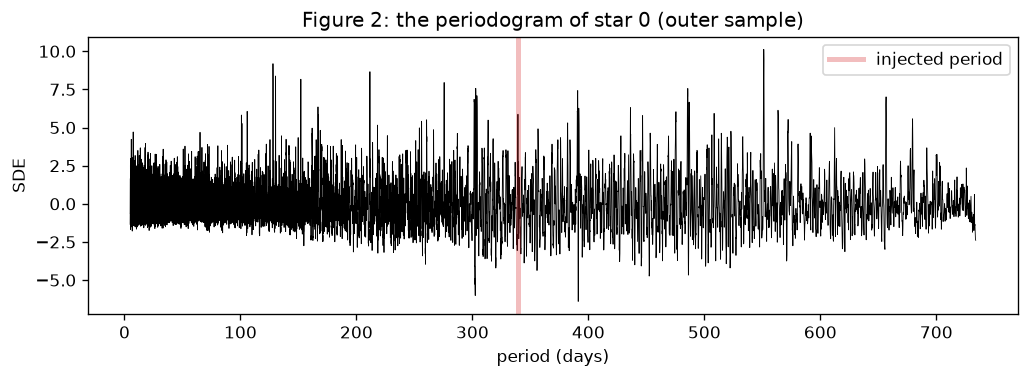

In [4]:
opts = tb.settings(stars["Radius"][star], stars["Mass"][star])
print(opts)
r = gp.search(t, fi, e, device=DEVICE, **opts)
inj = dict(P=row["Period"], T14=T14, transits=transits, n_tr=len(transits))
print(f"found: P = {r.period:.2f} d, T0 = {r.T0:.2f}, SDE {r.SDE:.1f}; recovered: {tb.recovered(inj, r, 'outer')}")

plt.figure(figsize=(10, 3))
plt.plot(r.periods, r.power, "k", lw=0.5)
plt.axvline(row["Period"], color="tab:red", alpha=0.3, lw=3, label="injected period")
plt.xlabel("period (days)"); plt.ylabel("SDE"); plt.legend()
plt.title("Figure 2: the periodogram of star 0 (outer sample)");

## Recovery criteria

As in Talens et al., without a detection threshold, the strongest peak counts as recovered if
* (their Eq. 4) the period, or a multiple of 1/2, 2 or 3 of it, accumulates a timing error of less than half the transit duration over all transits: $|P_\mathrm{inj} - n P| \, N_\mathrm{tr} < T_{14}/2$, or
* (their Eq. 5, outer sample with one or two transits) the recovered $T_0$ lies within half a duration of an injected transit.

We also report the recovery at a false-alarm rate of 1 %: the SDE threshold is the 99th percentile of the planet-free light curves (meaningful only with all 500).

## Run

In [5]:
tb.run(DATA_DIR, RESULTS, n=N_STARS, device=DEVICE, workers=WORKERS)

9 experiments to run (0 done)


inner star    0: P = 137.310 d, SDE 41.6, recovered: True (0.5 s)


inner star    1: P = 22.261 d, SDE 7.9, recovered: False (0.6 s)


inner star    2: P = 37.745 d, SDE 67.8, recovered: True (0.7 s)


outer star    0: P = 551.224 d, SDE 10.1, recovered: False (0.5 s)


outer star    1: P = 485.317 d, SDE 21.2, recovered: True (0.5 s)


outer star    2: P = 270.168 d, SDE 59.0, recovered: True (0.6 s)


noise star    0: P = 130.286 d, SDE 8.5 (0.4 s)


noise star    1: P = 22.261 d, SDE 7.9 (0.5 s)


noise star    2: P = 385.872 d, SDE 8.3 (0.7 s)


In [6]:
s = tb.summary(RESULTS)
print(f"{'':42s} {'inner':>8s} {'outer':>8s}")
print(f"{'TLS 2.0 + GP (this run)':42s} {s['inner']['recovered']:7.1f}% {s['outer']['recovered']:7.1f}%   "
      f"({s['inner']['n']} and {s['outer']['n']} planets)")
if s["threshold"] is not None and s["n_noise"] >= 500:
    print(f"{'  at 1 % false alarms':42s} {s['inner']['recovered_fap']:7.1f}% {s['outer']['recovered_fap']:7.1f}%   "
          f"(SDE >= {s['threshold']:.1f})")
for k, (a, b) in tb.PUBLISHED.items():
    print(f"{k + ' (Talens et al.)':42s} {a:7.1f}% {b:7.1f}%")

                                              inner    outer
TLS 2.0 + GP (this run)                       66.7%    66.7%   (3 and 3 planets)
nuance (Talens et al.)                        68.7%    53.8%
CETRA, best Huber spline (Talens et al.)      65.5%    46.1%
umbra, best Huber spline (Talens et al.)      66.3%    50.5%
CETRA, six Huber splines (Talens et al.)      69.6%    56.1%
umbra, six Huber splines (Talens et al.)      71.6%    59.7%


With a few stars, these percentages are of course not meaningful (the binomial uncertainty of the full benchmark is about 1 %). Set `N_STARS = None` to run all of it.

## Recovery against the planet radius

Meaningful with the full benchmark; with a few stars, the figure only shows the individual planets.

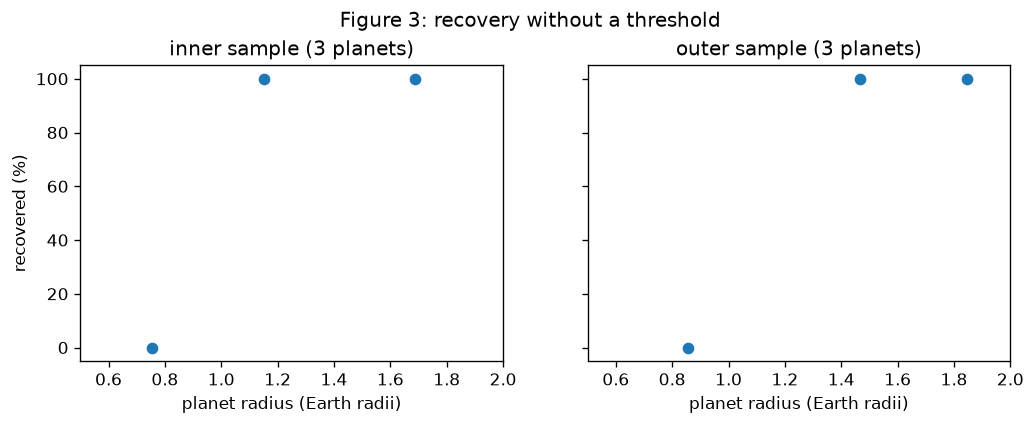

In [7]:
recs = list(tb.done(RESULTS).values())
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
edges = np.array([0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0001])
for a, sample in zip(ax, ("inner", "outer")):
    x = [r for r in recs if r["sample"] == sample]
    rp = np.array([r["inj"]["R_planet"] for r in x])
    found = np.array([r["recovered"] for r in x])
    if len(x) >= 100:
        k = np.digitize(rp, edges) - 1
        frac = [100 * found[k == i].mean() if (k == i).any() else np.nan for i in range(len(edges) - 1)]
        a.plot(0.5 * (edges[1:] + edges[:-1]), frac, "o-", color="tab:blue")
    else:
        a.plot(rp, 100 * found, "o", color="tab:blue")
    a.set_xlabel("planet radius (Earth radii)"); a.set_title(f"{sample} sample ({len(x)} planets)")
    a.set_xlim(0.5, 2.0)
ax[0].set_ylabel("recovered (%)")
fig.suptitle("Figure 3: recovery without a threshold", y=1.02);